# Phase 5 - Model Evaluation

Phase 4 trained and saved a Linear Regression baseline. In this phase, we evaluate how well it predicts sales on training rows and on the held-out test rows, inspect its errors, and record limitations before changing the model in Phase 6.

The evaluation reuses the model and train/test split saved by Phase 4. It does not refit the model or create a new split. The random split is useful for this learning baseline, but it is not a time-based test of future forecasting.

**Workflow:** Phase 1 data understanding -> Phase 2 EDA -> Phase 3 feature engineering -> Phase 4 baseline model -> **Phase 5 evaluation** -> Phase 6 model improvement.


## 5.1 Load Phase 4 artifacts and evaluation data

The model is stored in `models/sales_linear_regression.pkl`; Phase 4's split is stored as `X_train.csv`, `y_train.csv`, `X_test.csv`, and `y_test.csv` in `data`. The saved row index is read back so actual targets stay aligned with their feature rows. These are the already-prepared data used in training, not a new split.

We also load Phase 4's saved test predictions as a consistency check. The evaluation notebook will regenerate predictions with the loaded model and check that they match those saved values.


In [ ]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

PROJECT_DIR = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
MODEL_PATH = PROJECT_DIR / "models" / "sales_linear_regression.pkl"
PREDICTIONS_PATH = PROJECT_DIR / "models" / "linear_regression_test_predictions.csv"
PLOT_DIR = PROJECT_DIR / "plots" / "model evaluation"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

required_paths = [
    MODEL_PATH,
    PREDICTIONS_PATH,
    DATA_DIR / "X_train.csv",
    DATA_DIR / "y_train.csv",
    DATA_DIR / "X_test.csv",
    DATA_DIR / "y_test.csv",
]
missing_paths = [path for path in required_paths if not path.is_file()]
if missing_paths:
    raise FileNotFoundError(f"Required Phase 4 artifacts are missing: {missing_paths}")

model = joblib.load(MODEL_PATH)
X_train = pd.read_csv(DATA_DIR / "X_train.csv", index_col=0)
y_train_df = pd.read_csv(DATA_DIR / "y_train.csv", index_col=0)
X_test = pd.read_csv(DATA_DIR / "X_test.csv", index_col=0)
y_test_df = pd.read_csv(DATA_DIR / "y_test.csv", index_col=0)
saved_test_predictions = pd.read_csv(PREDICTIONS_PATH)

if list(y_train_df.columns) != ["Sales"] or list(y_test_df.columns) != ["Sales"]:
    raise ValueError("Expected Phase 4 target files to contain exactly one 'Sales' column.")
if list(X_train.columns) != list(model.feature_names_in_):
    raise ValueError("Training feature columns do not match those used to fit the saved model.")
if list(X_test.columns) != list(model.feature_names_in_):
    raise ValueError("Test feature columns do not match those used to fit the saved model.")
if not X_train.index.equals(y_train_df.index) or not X_test.index.equals(y_test_df.index):
    raise ValueError("Feature and target row indexes do not match in the saved Phase 4 splits.")

y_train = y_train_df["Sales"]
y_test = y_test_df["Sales"]
if len(X_train) != len(y_train) or len(X_test) != len(y_test):
    raise ValueError("Feature and target row counts do not match.")
if X_train.isna().any().any() or X_test.isna().any().any() or y_train.isna().any() or y_test.isna().any():
    raise ValueError("Saved Phase 4 splits contain missing values.")
if list(saved_test_predictions.columns) != ["Actual", "Predicted"]:
    raise ValueError("Expected Phase 4 saved predictions to have 'Actual' and 'Predicted' columns.")

print(f"Loaded model: {MODEL_PATH}")
print(f"Training rows: {len(X_train):,}; test rows: {len(X_test):,}")
print(f"Features ({len(model.feature_names_in_)}): {list(model.feature_names_in_)}")
print(f"Evaluation plots will be saved to: {PLOT_DIR}")


Loaded model: e:\NIAI\Projects\Retail Sales Prediction\models\sales_linear_regression.pkl
Training rows: 675,513; test rows: 168,879
Features (9): ['Store', 'Customers', 'Promo', 'SchoolHoliday', 'Year', 'Month', 'Day', 'WeekOfYear', 'IsWeekend']
Evaluation plots will be saved to: e:\NIAI\Projects\Retail Sales Prediction\plots\model evaluation


## 5.2 Generate predictions and residuals

A residual is the signed difference between the observed and predicted sales:

$$\text{Residual} = \text{Actual} - \text{Predicted}$$

A positive residual means the model underpredicted; a negative residual means it overpredicted. We generate predictions for both the training and test sets so their performance can be compared. Test predictions are checked against the values exported at the end of Phase 4.


In [ ]:
y_train_pred = model.predict(X_train)
y_pred = model.predict(X_test)

if len(saved_test_predictions) != len(y_test):
    raise ValueError("Saved Phase 4 predictions do not match the number of held-out test rows.")
np.testing.assert_allclose(
    saved_test_predictions["Actual"].to_numpy(),
    y_test.to_numpy(),
    rtol=0,
    atol=0,
    err_msg="Saved Phase 4 actual values do not match the saved test targets.",
)
np.testing.assert_allclose(
    saved_test_predictions["Predicted"].to_numpy(),
    y_pred,
    rtol=1e-10,
    atol=1e-8,
    err_msg="Reloaded model predictions do not match the Phase 4 predictions.",
)

residuals = y_test.to_numpy() - y_pred
print("Phase 4 held-out actual values and model predictions match.")
print(f"Training predictions: {len(y_train_pred):,}; test predictions: {len(y_pred):,}")
print("First five test residuals:", residuals[:5])


Phase 4 held-out actual values and model predictions match.
Training predictions: 675,513; test predictions: 168,879
First five test residuals: [ 1603.52237334   360.53804346   -77.16314124 -2360.13484822
   739.82171163]


## 5.3 Understand the primary metrics

- **MAE (Mean Absolute Error):** the average absolute prediction error, in sales units. It is straightforward to explain and treats each absolute error linearly.
- **MSE (Mean Squared Error):** the average squared error. Its squared units are less intuitive, and squaring gives large errors extra influence.
- **RMSE (Root Mean Squared Error):** the square root of MSE, so it returns to sales units while still penalizing large errors more than MAE does.
- **R² (coefficient of determination):** compares model predictions with predicting the test-set mean. It is not a percent accuracy score; negative values are possible when predictions are worse than that mean baseline.

There is no universal threshold for a 'good' score. Interpret errors in the context of sales scale and business needs, and use the training/test comparison and plots to understand model behavior.

In [ ]:
train_mae = mean_absolute_error(y_train, y_train_pred)
train_mse = mean_squared_error(y_train, y_train_pred)
train_rmse = np.sqrt(train_mse)
train_r2 = r2_score(y_train, y_train_pred)

test_mae = mean_absolute_error(y_test, y_pred)
test_mse = mean_squared_error(y_test, y_pred)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(y_test, y_pred)

metrics = {
    "Train MAE": train_mae,
    "Train MSE": train_mse,
    "Train RMSE": train_rmse,
    "Train R²": train_r2,
    "Test MAE": test_mae,
    "Test MSE": test_mse,
    "Test RMSE": test_rmse,
    "Test R²": test_r2,
}
metrics_df = pd.DataFrame(
    [
        {"Split": "Training", "MAE": train_mae, "MSE": train_mse, "RMSE": train_rmse, "R²": train_r2},
        {"Split": "Test", "MAE": test_mae, "MSE": test_mse, "RMSE": test_rmse, "R²": test_r2},
    ]
).set_index("Split")

print("MODEL EVALUATION")
print("=" * 60)
display(metrics_df.round(4))


MODEL EVALUATION


,MAE,MSE,RMSE,R²
Split,,,,
Training,1149.5567,2.598570e+06,1612.0081,0.7306
Test,1146.0445,2.567076e+06,1602.2099,0.7327


### Reading MAE and RMSE

MAE describes a typical absolute miss in sales units. RMSE is also in sales units, but it grows more when a few predictions have especially large errors. When RMSE is much larger than MAE, inspect the tail of the error distribution and the worst cases rather than relying on the average alone.

R² describes explained variation relative to a mean-only baseline on the same split. It should be reported as a score, not interpreted as exact prediction accuracy or a guarantee of future performance.

## 5.4 Build a row-level evaluation table

Keeping actual values, predictions, signed residuals, and absolute errors together makes it possible to inspect individual mistakes. The table is built from the held-out test observations only.

In [ ]:
evaluation_df = pd.DataFrame(
    {
        "Actual": y_test.to_numpy(),
        "Predicted": y_pred,
    },
    index=y_test.index,
)
evaluation_df.index.name = "Source row"
evaluation_df["Residual"] = evaluation_df["Actual"] - evaluation_df["Predicted"]
evaluation_df["Absolute_Error"] = evaluation_df["Residual"].abs()
evaluation_df.head(10)


,Actual,Predicted,Residual,Absolute_Error
Source row,,,,
378347,6782,5178.477627,1603.522373,1603.522373
866701,7675,7314.461957,360.538043,360.538043
114996,6669,6746.163141,-77.163141,77.163141
10163,7355,9715.134848,-2360.134848,2360.134848
548301,4533,3793.178288,739.821712,739.821712
638330,7721,7658.685643,62.314357,62.314357
655120,8151,6576.316675,1574.683325,1574.683325
490837,4404,6802.651594,-2398.651594,2398.651594
136470,5600,5605.499950,-5.499950,5.499950


## 5.5 Visualization 1 - Actual vs. predicted sales

Each point is one held-out store-day. The dashed diagonal represents perfect predictions (`Actual = Predicted`). Points near it have smaller errors; systematic departures above or below it can reveal underprediction or overprediction at particular sales levels.

Plot saved to: e:\NIAI\Projects\Retail Sales Prediction\plots\model evaluation\actual_vs_predicted_sales.png


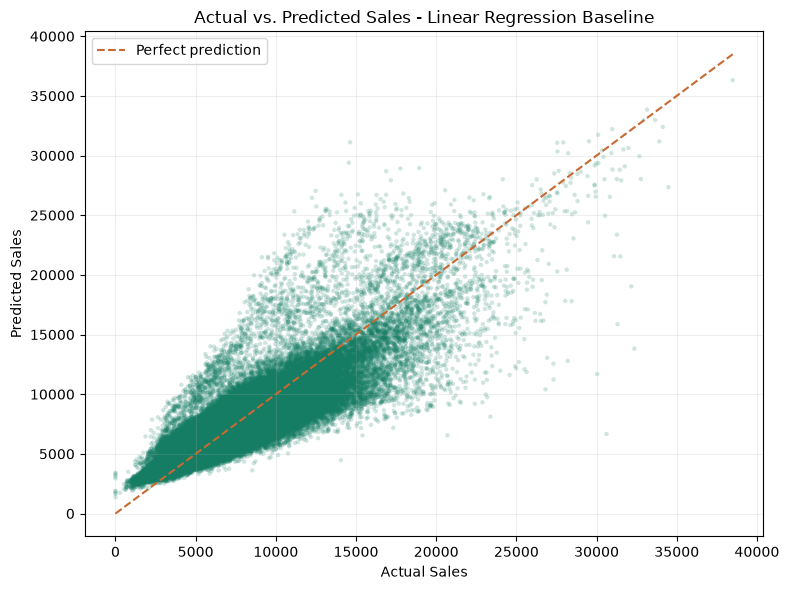

In [ ]:
plot_min = float(min(y_test.min(), y_pred.min()))
plot_max = float(max(y_test.max(), y_pred.max()))

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_test, y_pred, alpha=0.2, s=10, color="#147d64", edgecolors="none")
ax.plot([plot_min, plot_max], [plot_min, plot_max], "--", color="#c76a32", label="Perfect prediction")
ax.set_xlabel("Actual Sales")
ax.set_ylabel("Predicted Sales")
ax.set_title("Actual vs. Predicted Sales - Linear Regression Baseline")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
actual_predicted_plot_path = PLOT_DIR / "actual_vs_predicted_sales.png"
fig.savefig(actual_predicted_plot_path, dpi=200, bbox_inches="tight")
print(f"Plot saved to: {actual_predicted_plot_path}")
plt.show()


## 5.6 Visualization 2 - Residual distribution

A useful residual distribution is generally centered near zero. A skewed shape or long tails can indicate systematic bias or large errors. This histogram summarizes error sizes and direction; it does not by itself prove that the model assumptions are satisfied.

Plot saved to: e:\NIAI\Projects\Retail Sales Prediction\plots\model evaluation\residual_distribution.png


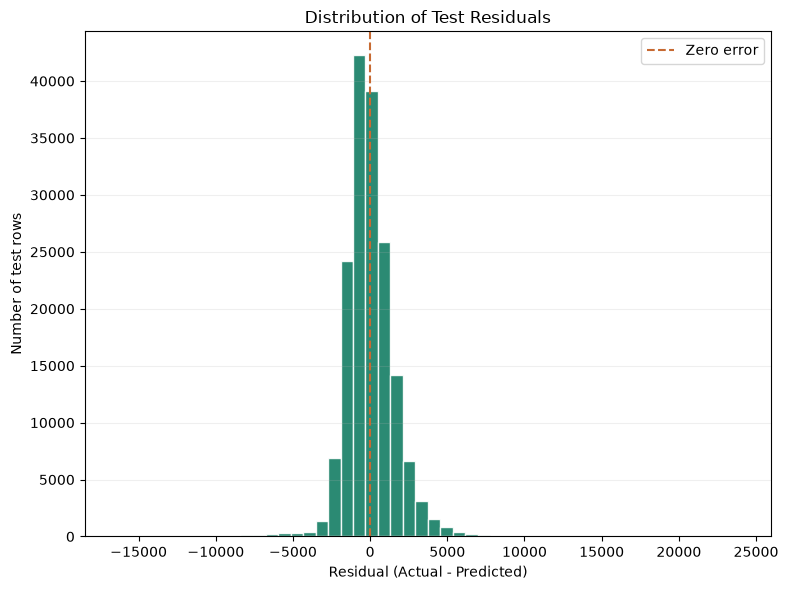

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.hist(residuals, bins=50, color="#147d64", edgecolor="white", alpha=0.9)
ax.axvline(0, color="#c76a32", linestyle="--", label="Zero error")
ax.set_xlabel("Residual (Actual - Predicted)")
ax.set_ylabel("Number of test rows")
ax.set_title("Distribution of Test Residuals")
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
residual_distribution_path = PLOT_DIR / "residual_distribution.png"
fig.savefig(residual_distribution_path, dpi=200, bbox_inches="tight")
print(f"Plot saved to: {residual_distribution_path}")
plt.show()


## 5.7 Visualization 3 - Residuals vs. predicted sales

Look for a roughly pattern-free cloud around the zero line. Curves, clusters, or a widening/narrowing spread can indicate relationships or changing error variance that the current model does not capture.

Plot saved to: e:\NIAI\Projects\Retail Sales Prediction\plots\model evaluation\residuals_vs_predicted.png


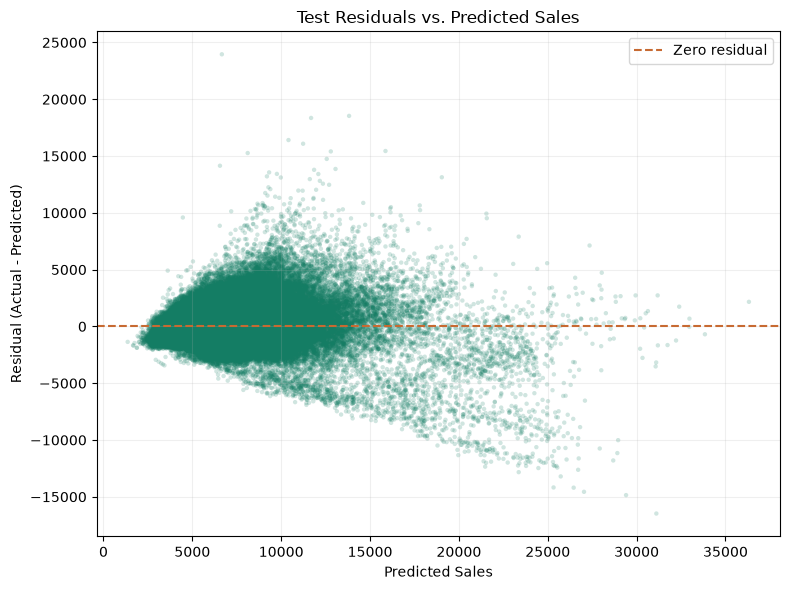

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_pred, residuals, alpha=0.2, s=10, color="#147d64", edgecolors="none")
ax.axhline(0, color="#c76a32", linestyle="--", label="Zero residual")
ax.set_xlabel("Predicted Sales")
ax.set_ylabel("Residual (Actual - Predicted)")
ax.set_title("Test Residuals vs. Predicted Sales")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
residuals_vs_predicted_path = PLOT_DIR / "residuals_vs_predicted.png"
fig.savefig(residuals_vs_predicted_path, dpi=200, bbox_inches="tight")
print(f"Plot saved to: {residuals_vs_predicted_path}")
plt.show()


## 5.8 Mean residual and worst predictions

The mean test residual indicates average signed bias: positive means underprediction on average, negative means overprediction. It need not be exactly zero on held-out data. Sorting by absolute error surfaces the test observations where this baseline missed the most.

In [ ]:
mean_residual = float(evaluation_df["Residual"].mean())
print(f"Mean test residual: {mean_residual:,.2f} sales units")
print("Positive means underprediction; negative means overprediction.")

worst_predictions = evaluation_df.sort_values("Absolute_Error", ascending=False).head(10)
worst_predictions


Mean test residual: -9.17 sales units
Positive means underprediction; negative means overprediction.


,Actual,Predicted,Residual,Absolute_Error
Source row,,,,
114901,30619,6661.140467,23957.859533,23957.859533
236684,32355,13819.792367,18535.207633,18535.207633
827590,30038,11683.007166,18354.992834,18354.992834
699749,14635,31109.273311,-16474.273311,16474.273311
586372,26818,10410.232693,16407.767307,16407.767307
274745,27318,11233.622459,16084.377541,16084.377541
660726,31311,15868.262395,15442.737605,15442.737605
766766,28198,12791.637938,15406.362062,15406.362062
316612,23379,8115.303708,15263.696292,15263.696292


## 5.9 Optional metric - MAPE (use with caution)

MAPE divides each absolute error by its actual value. It is undefined when actual sales are zero and can become extremely large when actual sales are close to zero. Because open-store data may still contain zero-sales rows, this notebook reports MAPE only for nonzero actuals and reports how many rows were excluded. MAPE is supplementary; MAE, RMSE, and R² remain the primary metrics.

In [ ]:
nonzero_actual_mask = y_test.to_numpy() != 0
zero_actual_count = int((~nonzero_actual_mask).sum())
if nonzero_actual_mask.any():
    mape_nonzero_actual = float(
        np.mean(
            np.abs(
                (y_test.to_numpy()[nonzero_actual_mask] - y_pred[nonzero_actual_mask])
                / y_test.to_numpy()[nonzero_actual_mask]
            )
        )
    )
    print(f"MAPE on nonzero actual sales: {mape_nonzero_actual:.4f} ({mape_nonzero_actual:.2%})")
else:
    mape_nonzero_actual = np.nan
    print("MAPE was not calculated because every actual test value is zero.")
print(f"Zero-actual rows excluded from MAPE: {zero_actual_count:,} of {len(y_test):,}")
print("Interpret MAPE cautiously: small nonzero actual values can still make it very large.")


MAPE on nonzero actual sales: 0.1799 (17.99%)
Zero-actual rows excluded from MAPE: 10 of 168,879
Interpret MAPE cautiously: small nonzero actual values can still make it very large.


## 5.10 Compare training and testing performance

Similar training and test scores suggest that performance is consistent across these two subsets. A much better training score than test score can be a sign of overfitting. If both are weak for the task, the model may be underfitting or missing useful information. These are diagnostic clues, not automatic pass/fail thresholds.

In [ ]:
train_test_comparison = pd.DataFrame(
    {
        "Metric": ["MAE", "RMSE", "R²"],
        "Training": [train_mae, train_rmse, train_r2],
        "Testing": [test_mae, test_rmse, test_r2],
    }
).set_index("Metric")
display(train_test_comparison.round(4))

r2_gap = train_r2 - test_r2
print(f"Training minus test R²: {r2_gap:.4f}")
if r2_gap > 0.05:
    print("The training R² is notably higher than test R²; investigate possible overfitting.")
elif abs(r2_gap) <= 0.05:
    print("Training and test R² are close on this random split; this does not establish future-date performance.")
else:
    print("Test R² exceeds training R² on this split; inspect split variability before drawing conclusions.")


## 5.11 Reusable evaluation function

This helper packages training and test MAE, RMSE, and R² into a dictionary for later reporting or a dashboard. It evaluates the provided model and data; it does not fit or modify the estimator.

In [ ]:
def evaluate_model(model, X_train, X_test, y_train, y_test):
    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    return {
        "Train MAE": mean_absolute_error(y_train, train_predictions),
        "Train RMSE": np.sqrt(mean_squared_error(y_train, train_predictions)),
        "Train R²": r2_score(y_train, train_predictions),
        "Test MAE": mean_absolute_error(y_test, test_predictions),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_predictions)),
        "Test R²": r2_score(y_test, test_predictions),
    }

evaluation_results = evaluate_model(model, X_train, X_test, y_train, y_test)
evaluation_results


## 5.12 Limitations and interpretation

- This is a simple Linear Regression baseline, so it may not represent nonlinear sales patterns or interactions.
- The split is shuffled and random. Because sales are time-dependent, it does not show how well the model forecasts a later time period. A time-based validation belongs in a later modeling iteration.
- `Customers` is included as a feature, but the customer count may not be known when a real forecast is made. If it is only available after the trading day, using it for advance forecasting would cause target leakage for that use case.
- `Store` is treated as a numeric value in this baseline even though it is an identifier; the numeric distance between store IDs has no natural business meaning.
- MAPE can be unstable for zero or very small actual sales, so it is not a primary success measure here.

Do not change the model in this phase. Use these scores, plots, and limitations to decide what should be tested in Phase 6.

## 5.13 Initial conclusion

The following cell builds a concise, data-driven statement from the calculated test scores. It reports the observed scores without labeling them universally 'good' or claiming future forecasting ability.

In [ ]:
print(
    f"On the held-out random test split, the model's R² is {test_r2:.4f}. "
    f"Its average absolute error is {test_mae:,.2f} sales units (MAE), "
    f"and its RMSE is {test_rmse:,.2f} sales units. "
    f"Training R² is {train_r2:.4f}, compared with test R² {test_r2:.4f}."
)
print("These results describe this random holdout only, not a time-based forecast test.")
print("Phase 5 is complete. Phase 6 model changes have not started.")


On the held-out random test split, the model's R² is 0.7327. Its average absolute error is 1,146.04 sales units (MAE), and its RMSE is 1,602.21 sales units. Training R² is 0.7306, compared with test R² 0.7327.
These results describe this random holdout only, not a time-based forecast test.
Phase 5 is complete. Phase 6 model changes have not started.


## 5.14 Export evaluation results to the dashboard

The dashboard reads a compact JSON snapshot generated from this evaluation. The aggregate metrics and residual histogram use all test rows; scatter chart points are deterministically sampled so the dashboard remains responsive. Re-run this cell after rerunning evaluation to refresh the dashboard data.

In [ ]:
import json

dashboard_sample_size = min(5_000, len(evaluation_df))
dashboard_sample = evaluation_df.sample(n=dashboard_sample_size, random_state=42)
histogram_counts, histogram_edges = np.histogram(residuals, bins=50)
residual_histogram = [
    {
        "bin": f"{histogram_edges[index]:,.0f} to {histogram_edges[index + 1]:,.0f}",
        "count": int(histogram_counts[index]),
    }
    for index in range(len(histogram_counts))
]

dashboard_evaluation = {
    "status": "Evaluated",
    "source": "phase5-notebook",
    "metrics": {
        "r2": float(test_r2),
        "mae": float(test_mae),
        "rmse": float(test_rmse),
        "mse": float(test_mse),
        "mape": None if np.isnan(mape_nonzero_actual) else float(mape_nonzero_actual),
        "zeroActualExcluded": zero_actual_count,
    },
    "trainingMetrics": {
        "r2": float(train_r2),
        "mae": float(train_mae),
        "rmse": float(train_rmse),
        "mse": float(train_mse),
    },
    "trainingRows": int(len(y_train)),
    "testingRows": int(len(y_test)),
    "meanResidual": mean_residual,
    "actualPredicted": [
        {"actual": float(row.Actual), "predicted": float(row.Predicted)}
        for row in dashboard_sample.itertuples(index=False)
    ],
    "residuals": [
        {"predicted": float(row.Predicted), "residual": float(row.Residual)}
        for row in dashboard_sample.itertuples(index=False)
    ],
    "residualHistogram": residual_histogram,
}

dashboard_data_dir = PROJECT_DIR / "frontend" / "public" / "data"
dashboard_data_dir.mkdir(parents=True, exist_ok=True)
dashboard_evaluation_path = dashboard_data_dir / "model-evaluation.json"
with dashboard_evaluation_path.open("w", encoding="utf-8") as dashboard_file:
    json.dump(dashboard_evaluation, dashboard_file, indent=2, allow_nan=False)

print(f"Dashboard evaluation data saved to: {dashboard_evaluation_path}")
print(f"Included {dashboard_sample_size:,} chart points and all {len(y_test):,} test rows in the metrics.")


Dashboard evaluation data saved to: e:\NIAI\Projects\Retail Sales Prediction\dashboard\public\data\model-evaluation.json
Included 5,000 chart points and all 168,879 test rows in the metrics.
